# MIPY quick start

From a data table to a benchmark of imputation methods, the completed data, figures and a report, in one call. This notebook uses the bundled example cohort (synthetic, laid out like the GSE65622 analysis files). Replace it with your own file in the last cell.

In [1]:
import mipy
print('mipy', mipy.__version__)

mipy 2.1.0


## 1. The example data

One row per patient visit: an ID, a visit, 120 protein columns with missing values, survival (`RFS`, `event`) and clinical columns.

In [2]:
df = mipy.example_cohort()
print(df.shape)
df.iloc[:6, :8]

(265, 128)


,Patient_ID,sampling_point,Prot_001,Prot_002,Prot_003,Prot_004,Prot_005,Prot_006
0,1,1,180.0646,2733.0124,392.0440,416.9655,259.7845,NaN
1,1,2,55.4159,513.3056,837.0504,281.1281,954.2963,1030.7551
2,1,4,86.8353,1502.9760,1086.8021,212.1810,864.4569,1496.7813
3,1,5,172.0260,NaN,530.4381,401.4087,452.4516,1312.0050
4,2,1,65.7913,430.4026,535.2016,272.5568,152.0924,797.9461
5,2,2,NaN,NaN,1067.7729,183.6250,271.3200,NaN


## 2. How MIPY reads the table

Nothing is imputed here. Check that the ID, visit, feature, clinical and survival columns are right; if not, pass `id_col=`, `time_col=`, `features=`, `clinical=` or `survival=`.

In [3]:
p = mipy.prepare_data(df)
for note in p.notes:
    print('-', note)
p.summary()

- ID column: 'Patient_ID' (found by name; pass id_col=... to change)
- visit column: 'sampling_point' (found by name; pass time_col=... to change)
- survival columns: time 'RFS', event 'event' (found by name; pass survival=False to skip the survival screen)
- clinical columns (few distinct values): trg_score, ypn_stage, ypt_stage, batch (pass clinical=... to change)
- values analysed as log2(x + 1) (all values above -1, largest above 50, as for raw intensities); results are written back on the original scale


,item,value
0,rows (patient visits),265
1,patients,80
2,features imputed,120
3,missing cells,"2,727 of 31,800 (8.58%)"
4,features with any missing value,120
5,ID column,Patient_ID
6,visit column,sampling_point
7,longitudinal methods,used
8,clinical columns,"trg_score, ypn_stage, ypt_stage, batch"
9,survival columns,RFS / event


## 3. Run the analysis

`methods="quick"` runs seven fast methods; the default `"standard"` runs eleven. Each mechanism is masked twice here (`repeats=2`); the default is 3. In Jupyter the tables and figures appear below when it finishes.

MIPY 2.1.0: analysis started 2026-10-16 13:23; results go to quickstart_results


1/7 checking the data


    ID column: 'Patient_ID' (found by name; pass id_col=... to change)


    visit column: 'sampling_point' (found by name; pass time_col=... to change)


    survival columns: time 'RFS', event 'event' (found by name; pass survival=False to skip the survival screen)


...

    5 completions for multiple imputation (MICE-Long)


6/7 exploratory survival screen


    survival screen: baseline sample of 80 patients, 40 events, univariate Cox per feature, pooled over 5 completions with Rubin's rules


7/7 writing figures, tables and the report


done in 2.0 min. Open quickstart_results/report.html


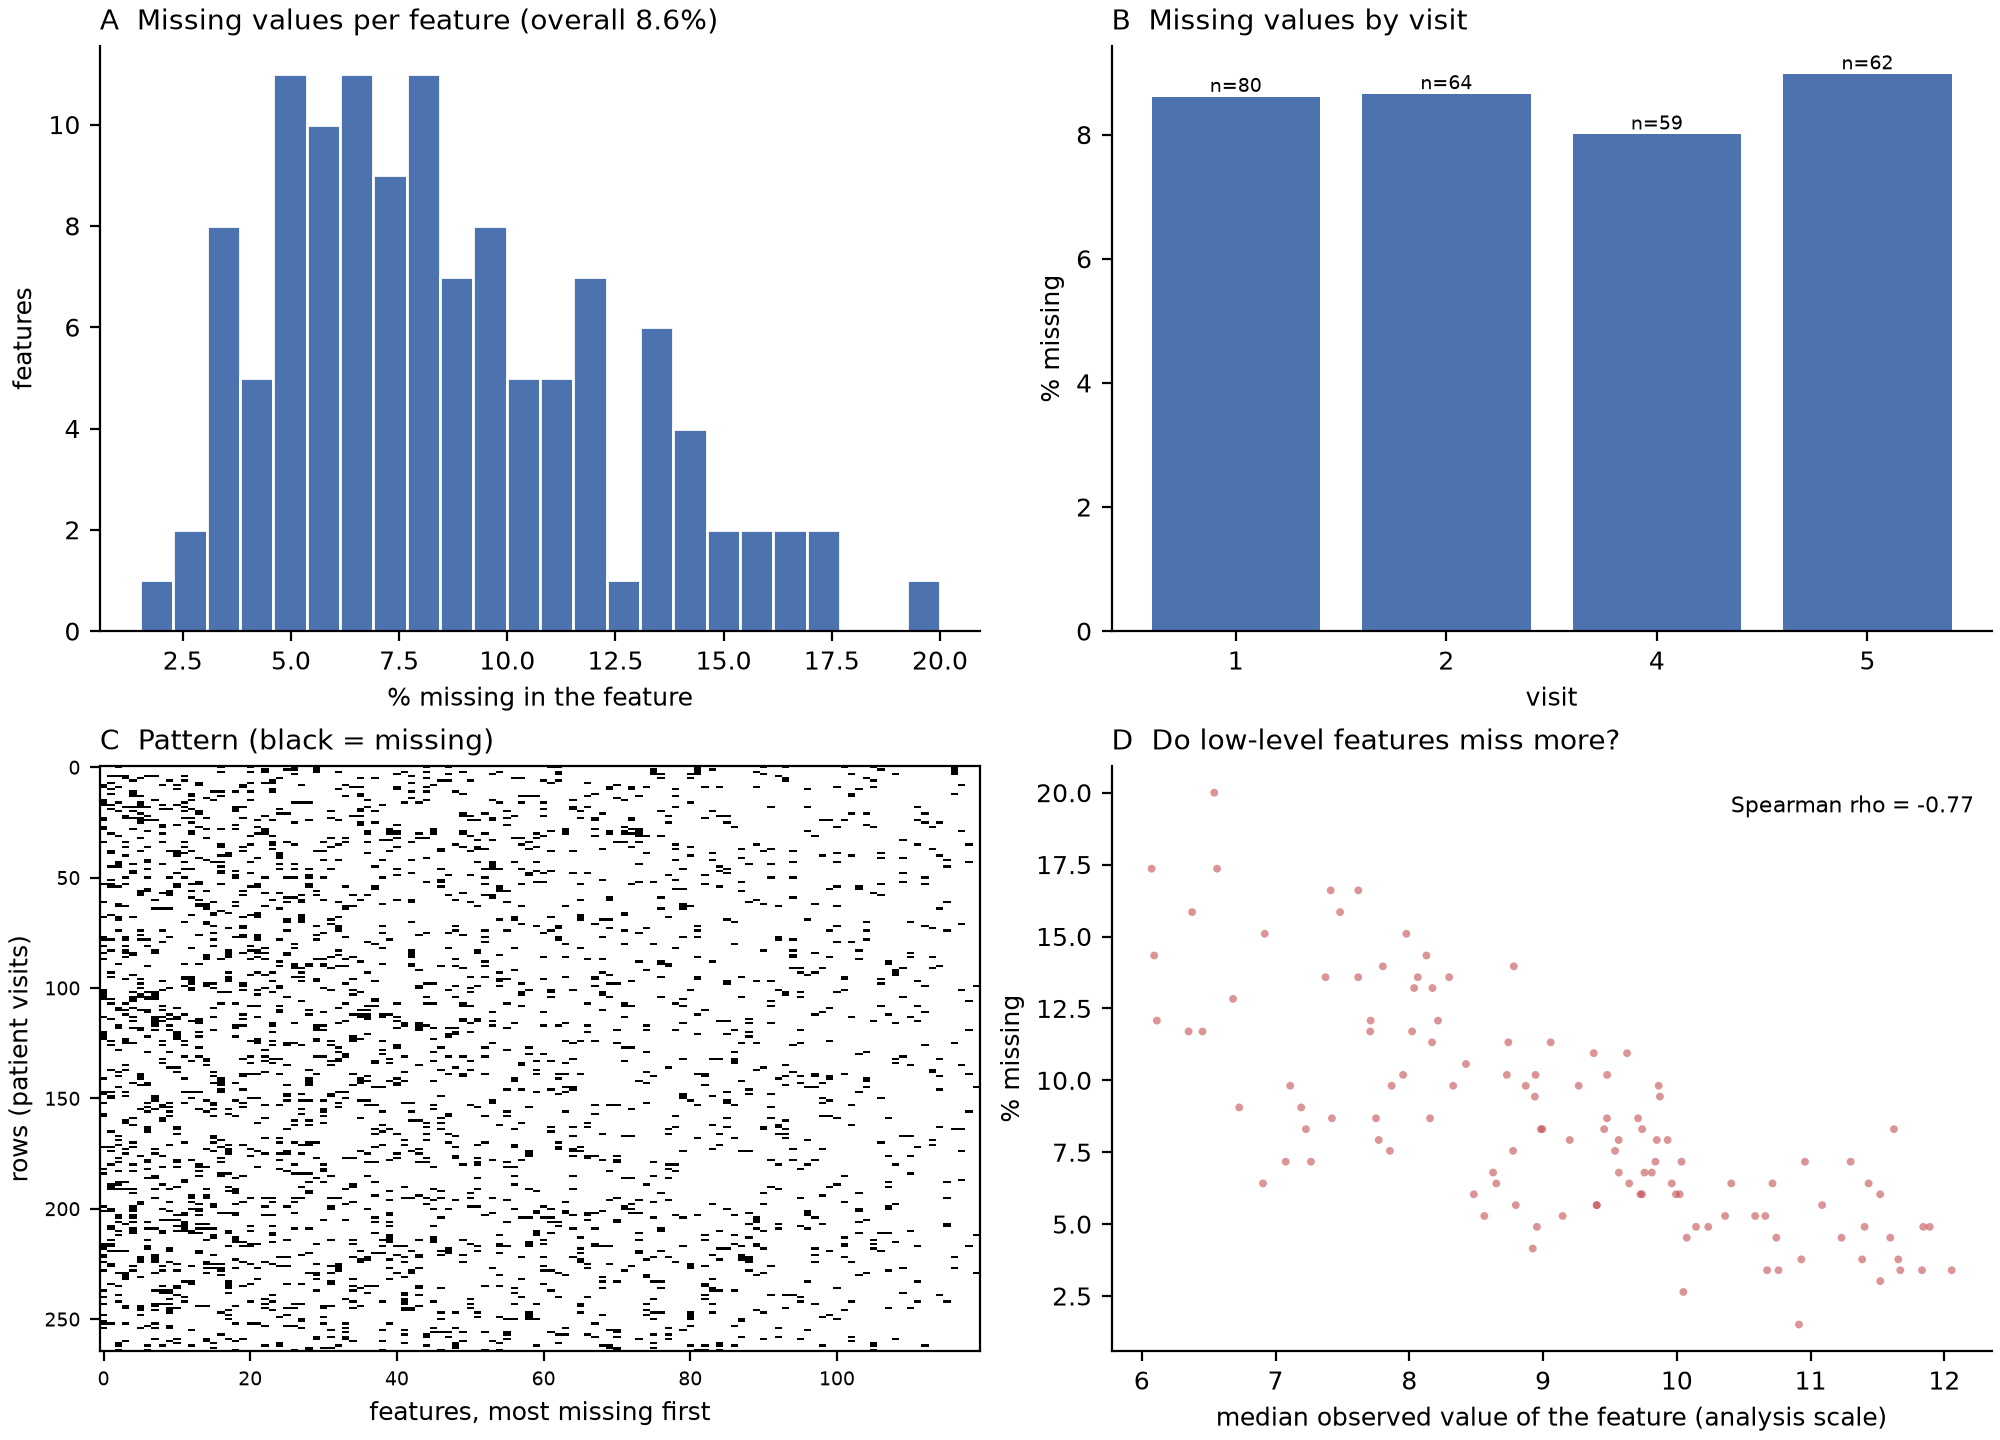

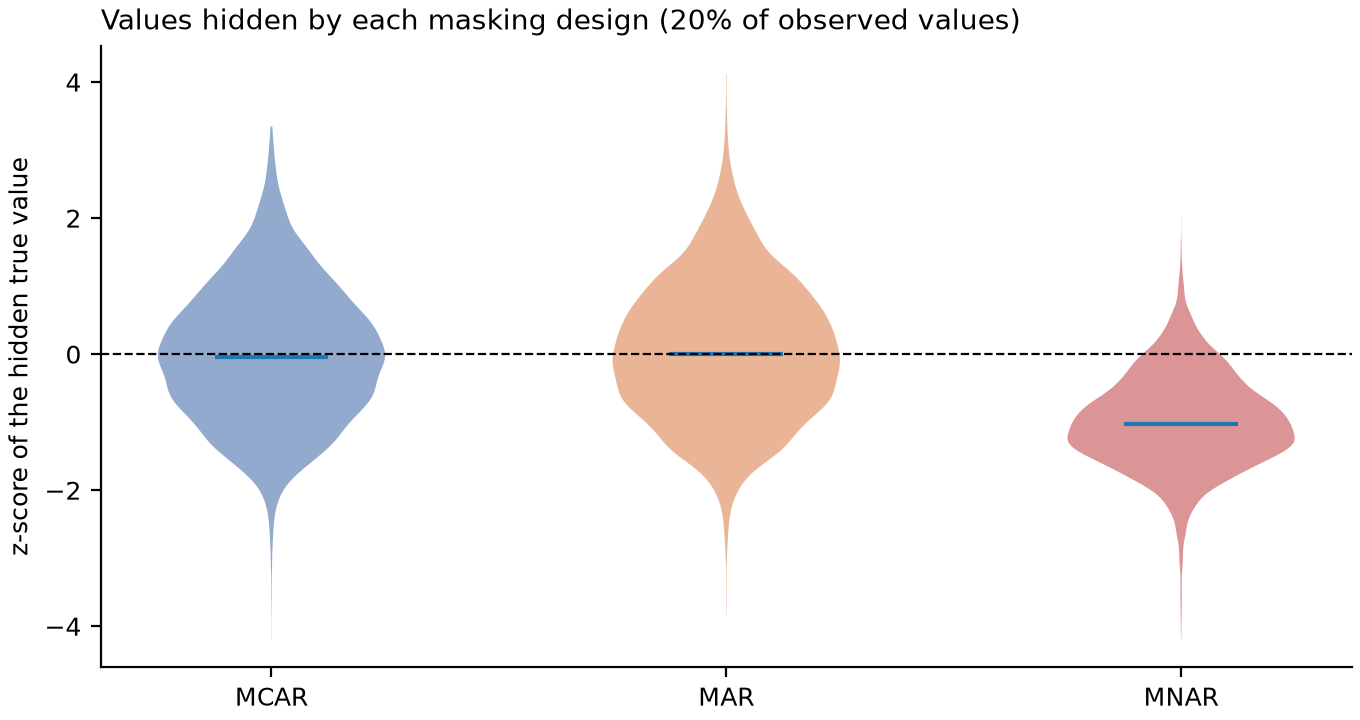

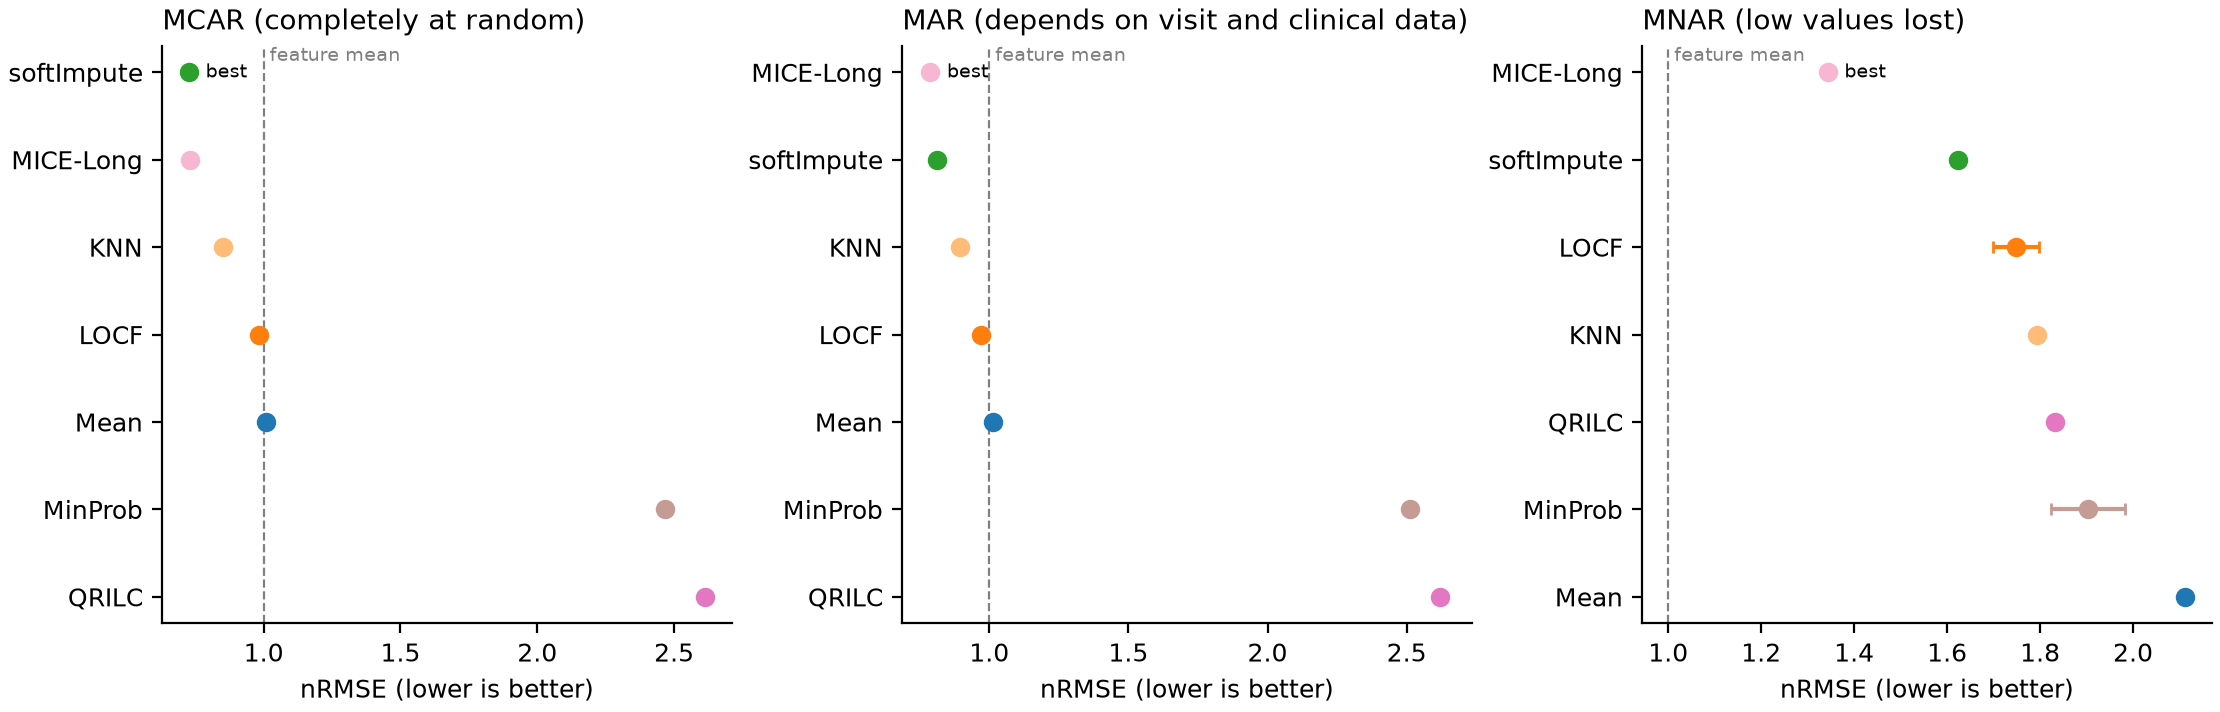

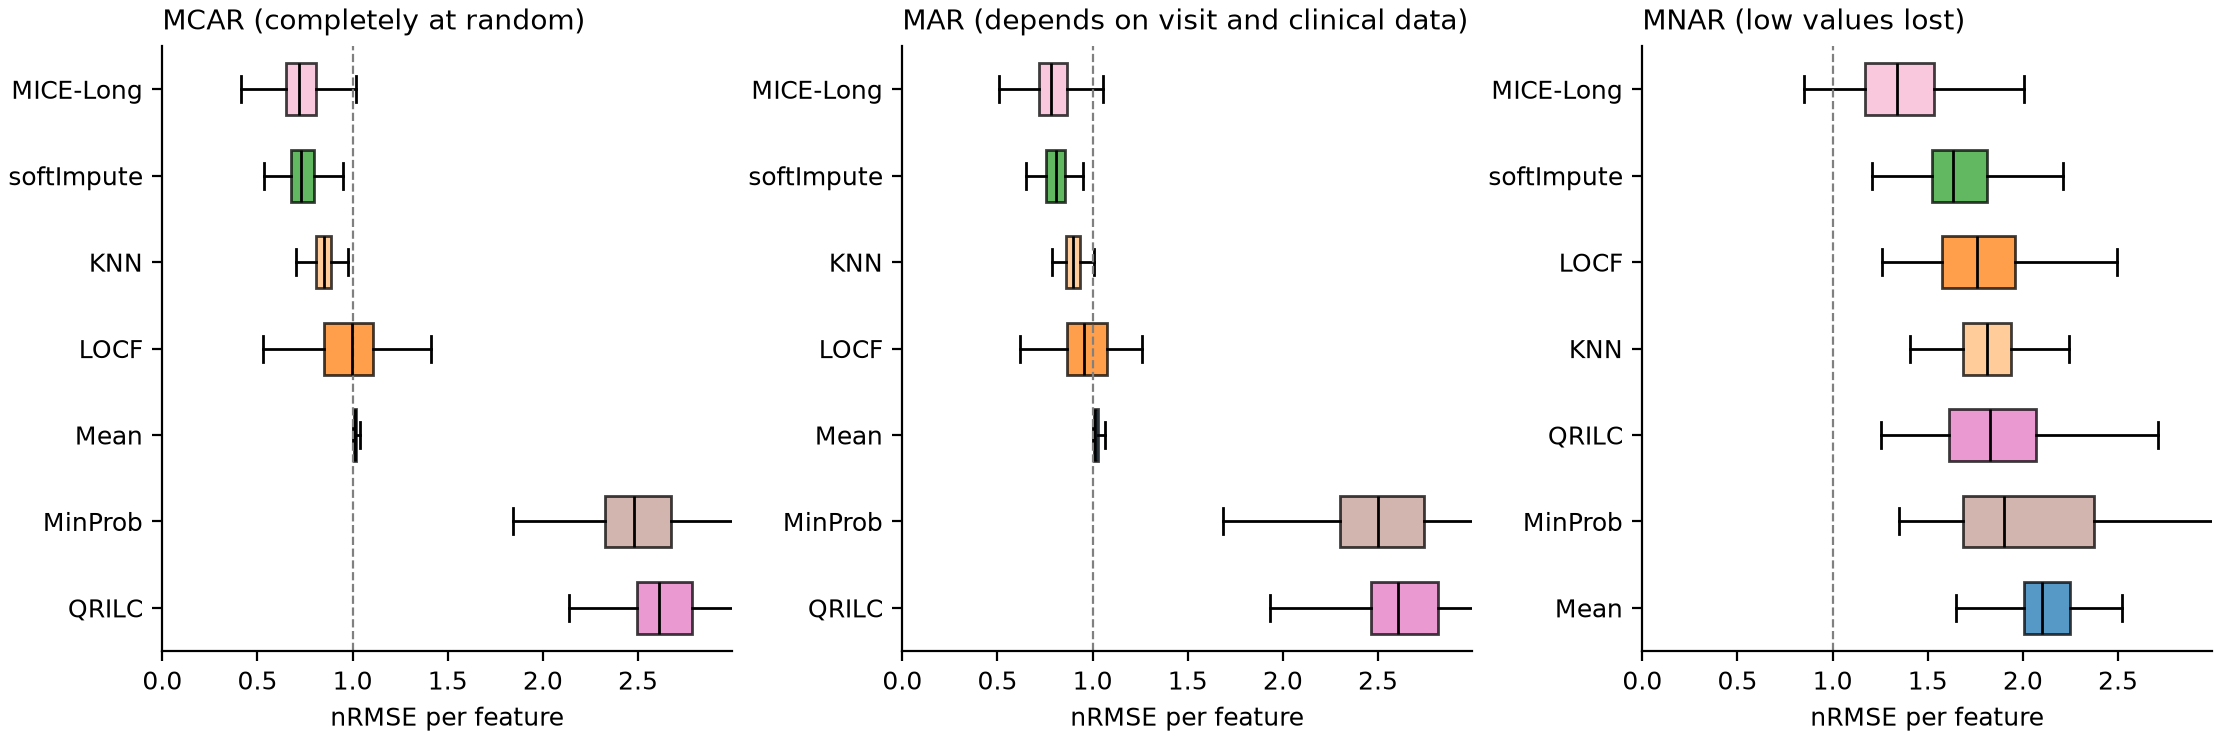

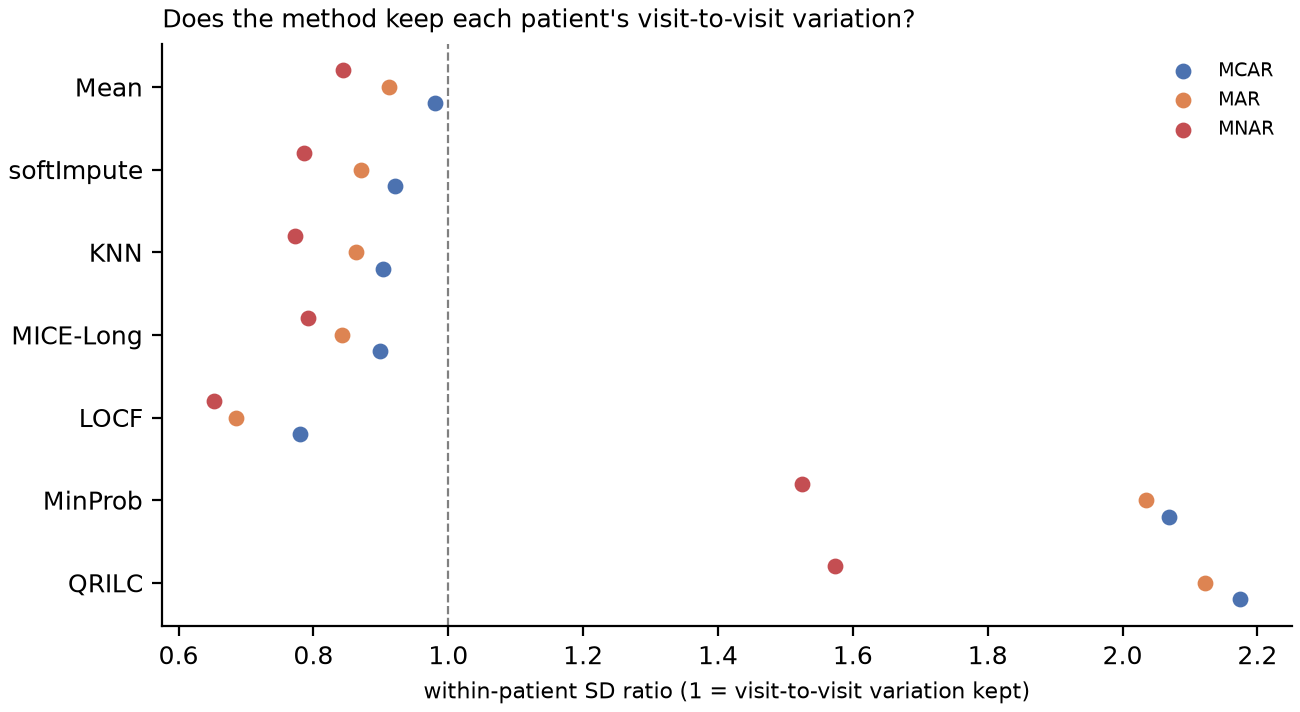

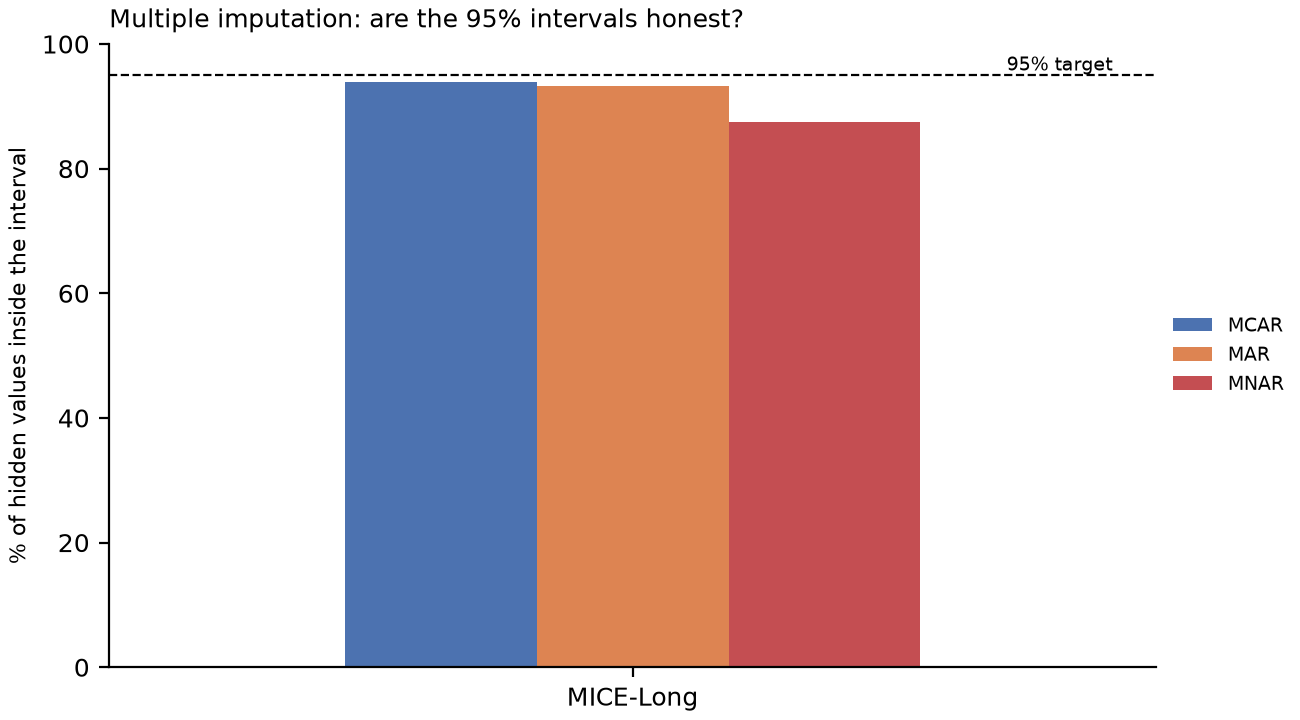

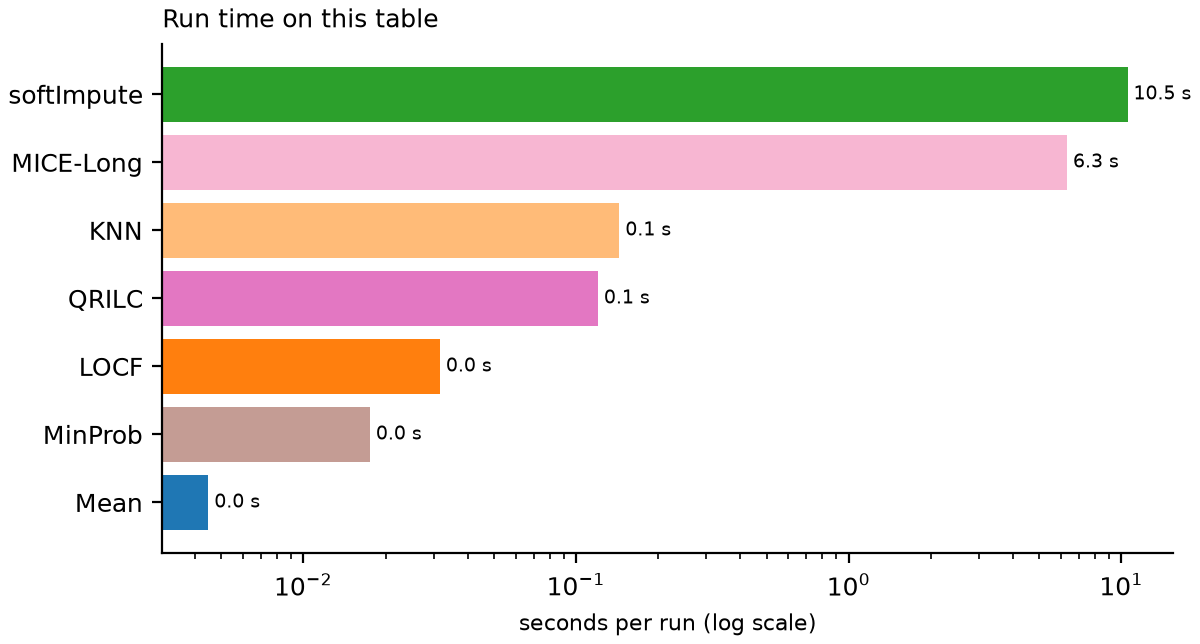

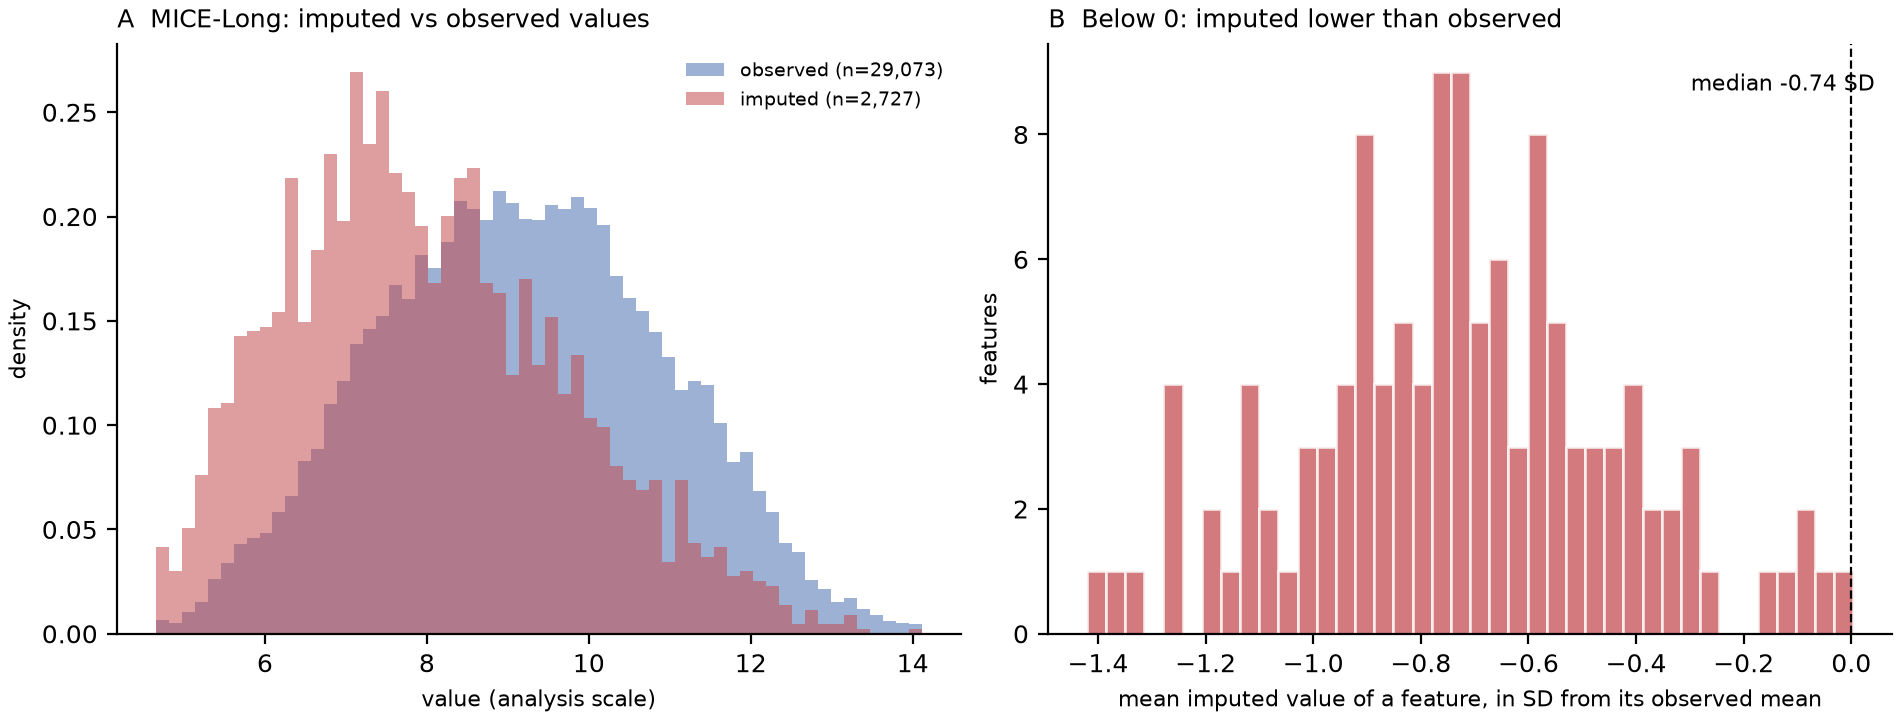

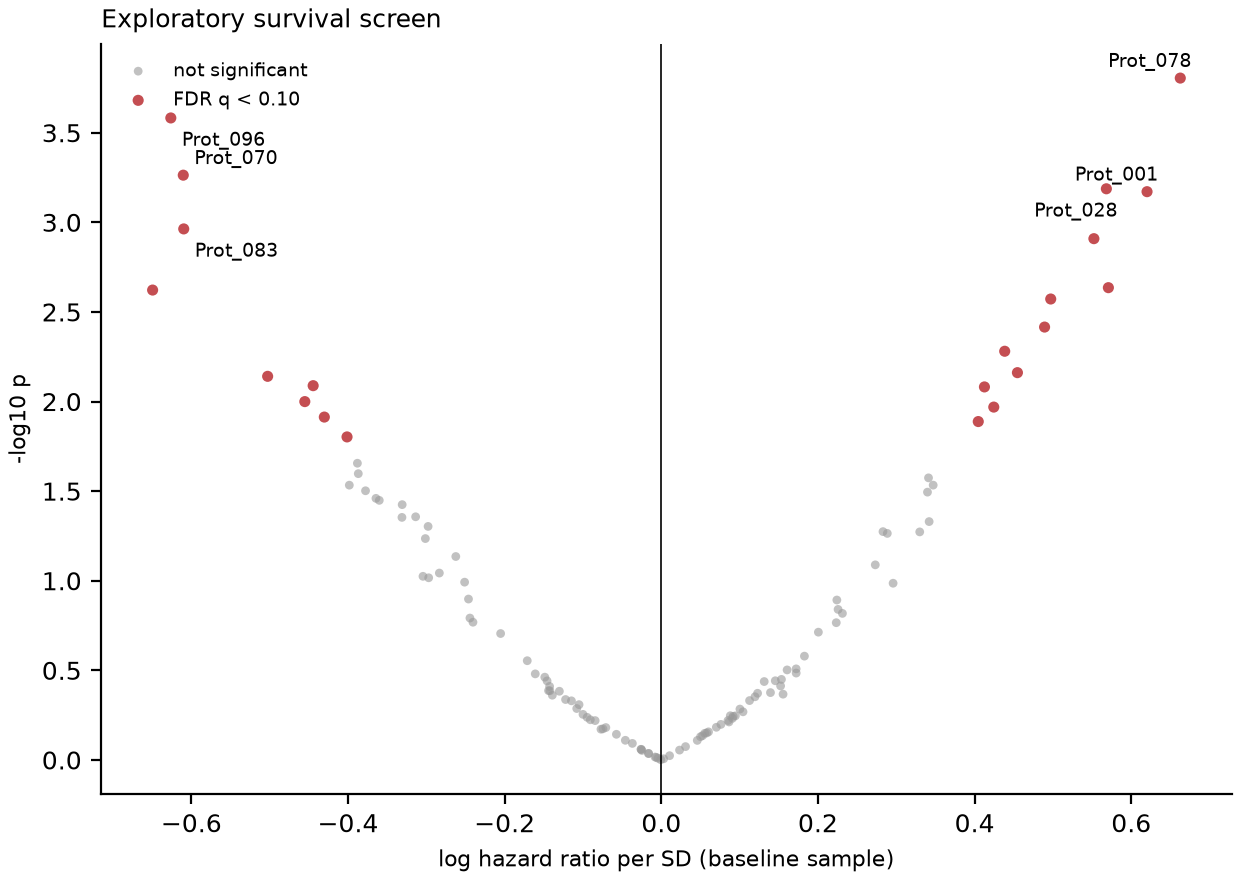

In [4]:
res = mipy.analyze(df, out='quickstart_results', methods='quick', repeats=2)

## 4. The results in Python

Best method under each assumption about why values are missing:

In [5]:
res.decision

,mechanism,best method,nRMSE,best in,runner-up,runner-up nRMSE,best multiple-imputation method,its coverage (%)
0,MCAR,softImpute,0.727078,1 of 2,MICE-Long,0.728977,MICE-Long,93.948691
1,MAR,MICE-Long,0.788282,2 of 2,softImpute,0.811409,MICE-Long,93.211258
2,MNAR,MICE-Long,1.343267,2 of 2,softImpute,1.622355,MICE-Long,87.561905


Every method under every mechanism (nRMSE: 1 = filling in the feature mean; lower is better):

In [6]:
res.summary[['mechanism', 'method', 'nRMSE', 'MCSE', 'best in', '% features nRMSE < 1', 'SD ratio', 'coverage (%)']].round(3)

,mechanism,method,nRMSE,MCSE,best in,% features nRMSE < 1,SD ratio,coverage (%)
0,MCAR,softImpute,0.727,0.001,1 of 2,100.000,0.920,NaN
1,MCAR,MICE-Long,0.729,0.002,1 of 2,97.083,0.899,93.949
2,MCAR,KNN,0.850,0.001,0 of 2,98.333,0.903,NaN
3,MCAR,LOCF,0.983,0.001,0 of 2,53.333,0.780,NaN
4,MCAR,Mean,1.008,0.001,0 of 2,0.000,0.980,NaN
5,MCAR,MinProb,2.467,0.011,0 of 2,0.000,2.069,NaN
6,MCAR,QRILC,2.612,0.002,0 of 2,0.000,2.175,NaN
7,MAR,MICE-Long,0.788,0.004,2 of 2,95.833,0.843,93.211
8,MAR,softImpute,0.811,0.002,0 of 2,99.167,0.870,NaN
9,MAR,KNN,0.894,0.002,0 of 2,95.833,0.864,NaN


The completed table (same rows, columns and order as the input; missing values filled in):

In [7]:
print('method:', res.completed_method, '| multiple imputation:', res.mi_method, len(res.completed_draws), 'completions')
res.completed.iloc[:6, :8]

method: MICE-Long | multiple imputation: MICE-Long 5 completions


,Patient_ID,sampling_point,Prot_001,Prot_002,Prot_003,Prot_004,Prot_005,Prot_006
0,1,1,180.064600,2733.012400,392.0440,416.9655,259.7845,1236.312947
1,1,2,55.415900,513.305600,837.0504,281.1281,954.2963,1030.755100
2,1,4,86.835300,1502.976000,1086.8021,212.1810,864.4569,1496.781300
3,1,5,172.026000,2365.105294,530.4381,401.4087,452.4516,1312.005000
4,2,1,65.791300,430.402600,535.2016,272.5568,152.0924,797.946100
5,2,2,70.738555,418.088572,1067.7729,183.6250,271.3200,761.212805


Exploratory survival screen (univariate Cox per protein on the baseline sample, pooled over the completions):

In [8]:
res.survival.head(10).round(4)

,feature,log_hr,HR per SD,se,p,fmi,q
0,Prot_078,0.6626,1.9398,0.1753,0.0002,0.0090,0.0157
1,Prot_096,-0.6262,0.5346,0.1715,0.0003,0.0131,0.0157
2,Prot_070,-0.6103,0.5432,0.1765,0.0005,0.0020,0.0162
3,Prot_028,0.5682,1.7651,0.1666,0.0006,0.0093,0.0162
4,Prot_001,0.6201,1.8592,0.1823,0.0007,0.0200,0.0162
5,Prot_083,-0.6097,0.5435,0.1866,0.0011,0.0187,0.0211
6,Prot_014,0.5523,1.7372,0.1703,0.0012,0.0709,0.0211
7,Prot_064,0.5708,1.7697,0.1867,0.0023,0.0721,0.0318
8,Prot_004,-0.6494,0.5224,0.2052,0.0024,0.2517,0.0318
9,Prot_030,0.4972,1.6441,0.1646,0.0027,0.0957,0.0321


Everything is also on disk:

In [9]:
import os
for root, dirs, files in os.walk('quickstart_results'):
    if '.mipy_cache' in root:
        continue
    for f in sorted(files):
        print(os.path.join(root, f))

quickstart_results/README.txt
quickstart_results/report.html
quickstart_results/run_log.txt
quickstart_results/tables/accuracy_overview.csv
quickstart_results/tables/accuracy_summary.csv
quickstart_results/tables/all_runs.csv
quickstart_results/tables/data_summary.csv
quickstart_results/tables/decision.csv
quickstart_results/tables/fmi.csv
quickstart_results/tables/masking.csv
quickstart_results/tables/methods.csv
quickstart_results/tables/mipy_results.xlsx
quickstart_results/tables/per_feature_nrmse.csv
quickstart_results/tables/survival_screen.csv
quickstart_results/figures/fig01_missingness.pdf
quickstart_results/figures/fig01_missingness.png
quickstart_results/figures/fig02_masking.pdf
quickstart_results/figures/fig02_masking.png
quickstart_results/figures/fig03_accuracy.pdf
quickstart_results/figures/fig03_accuracy.png
quickstart_results/figures/fig04_nrmse_per_feature.pdf
quickstart_results/figures/fig04_nrmse_per_feature.png
quickstart_results/figures/fig05_sd_ratio.pdf
quicksta

## 5. Your own data

```python
res = mipy.analyze(r"C:\path\to\my_data.csv", out="my_results")
```

or, naming the columns yourself:

```python
res = mipy.analyze("my_data.xlsx", id_col="Patient_ID", time_col="sampling_point",
                   survival=("RFS", "event"), out="my_results")
```

Then open `my_results/report.html` in a browser. See `docs/your_data.md` for every option.